## Review of SVD


Last time we showed that there exists a singular value decomposition in the form  $\bf{A=U{\Sigma}V^T} $. To result in this composition, we require  $\bf U $ as an orthogonal basis of  $\mathbb{R}^m $,  $\bf V $ as an orthogonal basis of  $\mathbb{R}^n $, and  $\bf{\Sigma} $ as an  $m \times n $ diagonal matrix, where  $\bf{Av_i = \sigma_iu_i} $.

*    ${\bf U} $ is an  $m \times m $ orthogonal matrix whose columns are eigenvectors of  ${\bf A} {\bf A}^T $, called the **left singular vectors** of  ${\bf A} $.

*    ${\bf V} $ is an  $n \times n $ orthogonal matrix whose columns are eigenvectors of  ${\bf A}^T {\bf A} $, called the **right singular vectors** of  ${\bf A} $.

*    ${\bf \Sigma} $ is an  $m \times n $ diagonal matrix, composed of the square root of the eigenvalues of  $A^TA $. The diagonal entries are called the **singular values** of  ${\bf A} $. **singular values are always non-negative**.


In addition, we define a reduced form:  ${\bf A} = {\bf U_{R}} {\bf \Sigma_{R}} {\bf V_R}^T $ where  ${\bf U_R} $ is an  $m \times k $ matrix,  ${\bf V_R} $ is an  $n \times k $ matrix, and  ${\bf \Sigma_{R}} $ is an  $k \times k $ diagonal matrix and  $k = \min(m,n) $.

The induced 2-norm of a matrix  ${\bf A} $ can be obtained using the SVD of the matrix:

\\[\begin{align} \| {\bf A} \|_2 &= \max_{\|y\|=1} \|\mathbf{ \Sigma} y\| \end{align}\\]

hence,

\\[\| {\bf A} \|_2= \sigma_1\\]

Following the same derivation as above, we can show that for a full rank  $n \times n $ matrix we have:

\\[\| {\bf A}^{-1} \|_2= \frac{1}{\sigma_n}\\]

where  ${\sigma_n} $ is the smallest singular value.

For non-square matrices, we can use the definition of the pseudoinverse (regardless of the rank):

\\[\| {\bf A}^{+} \|_2= \frac{1}{\sigma_r}\\]

where  ${\sigma_r} $ is the smallest **non-zero** singular value.


The 2-norm condition number of a matrix  ${\bf A} $ is given by the ratio of its largest singular value to its smallest singular value:

\\[\text{cond}_2(A) = \|{\bf A}\|_2 \|{\bf A}^{-1}\|_2 = \sigma_{\max}/\sigma_{\min}.\\]


The best rank- $k $ approximation for a  $m \times n $ matrix  ${\bf A} $, where  $k < s = \min(m,n) $, for some matrix norm  $\|.\| $, is one that minimizes the following problem:

\\[\begin{aligned} &\min_{ {\bf A}_k } \ \|{\bf A} - {\bf A}_k\| \\ &\textrm{such that} \quad \mathrm{rank}({\bf A}_k) \le k. \end{aligned}\\]

Under the induced  $2 $\-norm, the best rank- $k $ approximation is given by the sum of the first  $k $ outer products of the left and right singular vectors scaled by the corresponding singular value (where,  $\sigma_1 \ge \dots \ge \sigma_s $):

\\[{\bf A}_k = \sigma_1 \bf{u}_1 \bf{v}_1^T + \dots \sigma_k \bf{u}_k \bf{v}_k^T\\]


If  $\bf A $ is an  $n \times n $ square matrix and we want to solve  $\bf{Ax=b} $, we can use the SVD for A such that

\\[\bf{U{\Sigma}V^Tx=b}\\] \\[\bf{ {\Sigma} V^Tx=U^Tb}\\]

Solve:  $\bf{\Sigma y=U^Tb} $ (diagonal matrix, easy to solve)

Evaluate:  $\bf{x=Vy} $
  

In [62]:
from numpy import diag, zeros,vstack
from numpy.random import rand, seed
from numpy.linalg import svd, pinv

seed (12345)

n=5
p=8
X = rand(n,p)
y = rand(n,1)
U,S,VT = svd(X)
Sigma = diag(1/S)
# compute pseudo inverse
pseudo_inv = VT.T @ vstack((Sigma, zeros((p-n,n)))) @ U.T
b = pseudo_inv @ y
#b = pinv(X) @ y #remove comment for the built-in pseudo inverse
print(X @ b - y)

[[ 4.44089210e-16]
 [ 2.22044605e-16]
 [-1.11022302e-16]
 [ 7.77156117e-16]
 [ 7.21644966e-16]]


 **HW5-1:** Create a $100\times 100$ matrix of random numbers between 0 and 1
such that each entry is highly correlated with the adjacency entries. Find the SVD of the matrix. What fraction of the Frobenius norm of A is captured by the top 10 singular vectors? How many singular vectors are required to capture 95% of the Frobenius norm (the square root of the sum of the squares of all elements of the matrix)?
2. Repeat (1) with a $100\times 100$ matrix of statistically independent random numbers between 0 and 1.



**HW5-2:** (Finding Structure in Movie Ratings and Consumers): The 100K MovieLens dataset available at
https://grouplens.org/datasets/movielens/100k/. There are m = 1682 movies and n = 943 users. Each user rated at least 20 movies, but some watched many more. The total dataset contains 100, 000 total ratings from all users. Compute the singular value decomposition (SVD) corresponding matrix and suggest a way to capture the relationships of how people rate movies, and especially if there is a structure linking which people like which movies. You can interpret the left-singular vectors as stereotypical movies and
the right-singular vectors as stereotypical viewers. A specific movie is therefore represented by how it decomposes (linearly) into its stereotypical movies. Likewise, a person would be represented by how they decompose (via linear combination) into movie themes.


You can then make the assumption that any viewer's specific movie preferences can be expressed as a linear combination of the $v_j$. Similarly, any movie's like-ability can be expressed as a linear combination of the $u_i$. Therefore, a vector in the domain of the SVD can be interpreted as a viewer in the “space” of stereotypical viewers, and a vector in the codomain of the SVD correspondingly as a movie in the “space” of stereotypical movies. This can be the basis for recommending movies the users haven't seen (assuming that each
user would give a rating of 0 to any movie they have not reviewed). How can you use SVD to group a type of users with a specific set of movies?   

# Quadratic form

A _quadratic form_ is a function with form $Q(\mathbf{x})=\mathbf{x}^TA\mathbf{x}$, where $A$ is an $n\times n$ (often symmetric matrix), which is called the _the matrix of the quadratic form_.

-------

Consider the following quadratic equation:


$$f({x}) = ax_1^2 +(b+c)x_1x_2 + dx_2^2$$



------


These quadratic forms can be generated by matrices:

$$ f({x})= \begin{bmatrix}
    x_1 & x_2
\end{bmatrix}\begin{bmatrix}
    a & b\\\\
    c & d
\end{bmatrix}\begin{bmatrix}
    x_1\\\\
    x_2
\end{bmatrix} = {x^\text{T}Ax}$$



Note that the same quadratic form can be obtained from infinite number of matrices $A$ by changing $b$ and $c$ while preserving their sum. We usually
consider making $A$ symmetric.

### Example

$$ {x} = \begin{bmatrix}
    x_1\\\\
    x_2
\end{bmatrix}$$

and

$$ {A}=\begin{bmatrix}
    6 & 2\\\\
    2 & 3
\end{bmatrix}$$

$$\begin{align*}
{x^\text{T}Ax}&=
\begin{bmatrix}
    x_1 & x_2
\end{bmatrix}
\begin{bmatrix}
    6 & 2\\\\
    2 & 3
\end{bmatrix}
\begin{bmatrix}
    x_1\\\\
    x_2
\end{bmatrix}\\\\
&=
\begin{bmatrix}
    x_1 & x_2
\end{bmatrix}
\begin{bmatrix}
    6 x_1 + 2 x_2\\\\
    2 x_1 + 3 x_2
\end{bmatrix}\\\\
&=
x_1(6 x_1 + 2 x_2) + x_2(2 x_1 + 3 x_2)\\\\
&=
6 x_1^2 + 4 x_1x_2 + 3 x_2^2
\end{align*}$$

If $A$
 is a diagonal matrix, the quadratic form of ${x^\text{T}Ax}$
 will have no cross term.

To convert a matrix of quadratic form into diagonal matrix, i.e. no cross products terms, consider $A$, which is symmetric, so there is an orthonormal $P$ that

$$
PDP^T = A \qquad \text{and}\qquad PP^T = I
$$

We can show that

$$
\mathbf{x}^TA\mathbf{x}=\mathbf{x}^TIAI\mathbf{x}=\mathbf{x}^TPP^TAPP^T\mathbf{x}=\mathbf{x}^TPDP^T\mathbf{x}=(P^T\mathbf{x})^TDP^T\mathbf{x}=\mathbf{y}^T D \mathbf{y}$$

where $P^T$ defined a coordinate transformation and $\mathbf{y} = P^T\mathbf{x}$.

Consider $A$

$$
A =
\left[
\begin{matrix}
6 & 2\\
2 & 3
\end{matrix}
\right]
$$

Find eigenvalue and eigenvectors:

In [63]:
A = np.array([[6,2],[2,3]]); A

array([[6, 2],
       [2, 3]])

In [64]:
D, P = np.linalg.eig(A)
D = np.diag(D); D

array([[7., 0.],
       [0., 2.]])

Test if $P$ is normalized.

In [65]:
P.T@P

array([[1., 0.],
       [0., 1.]])

We can compute $\mathbf{y}= P^T\mathbf{x}$

In [66]:
import sympy as sy;
x1, x2 = sy.symbols('x1 x2')
x = sy.Matrix([[x1], [x2]])
x

Matrix([
[x1],
[x2]])

In [67]:
def round_expr(expr, num_digits):
    return expr.xreplace({n : round(n, num_digits) for n in expr.atoms(sy.Number)})
P = round_expr(sy.Matrix(P), 4); P

Matrix([
[0.8944, -0.4472],
[0.4472,  0.8944]])

In [68]:
y = P.T*x; y

Matrix([
[ 0.8944*x1 + 0.4472*x2],
[-0.4472*x1 + 0.8944*x2]])

The transformed quadratic form $\mathbf{y}^T D \mathbf{y}$ is

In [69]:
D =  round_expr(sy.Matrix(D),4);D

Matrix([
[7.0, 0.0],
[0.0, 2.0]])

In [70]:
y1, y2 = sy.symbols('y1 y2')
y = sy.Matrix([[y1], [y2]]);y

Matrix([
[y1],
[y2]])

In [71]:
y.T*D*y

Matrix([[7.0*y1**2 + 2.0*y2**2]])

This change of variable leads to removing the cross terms in our quadratic equation. Without the cross term, it will then be easier to characterize the function and eventually optimize it (i.e finding its maximum or minimum).

# The Principal Axes

We can use $D$ to simplify our quadratic equation and remove the cross terms:

 $$ {D}=
\begin{bmatrix}
    7 & 0\\\\
    0 & 2
\end{bmatrix}$$

$$ \begin{align*}
{x^\text{T}Ax}
&=
{y^\text{T}{D} y}\\\\
&=
{y}^\text{T}
\begin{bmatrix}
    7 & 0\\\\
    0 & 2
\end{bmatrix}
{y}\\\\
&=
\begin{bmatrix}
    y_1 & y_2
\end{bmatrix}
\begin{bmatrix}
    7 & 0\\\\
    0 & 2
\end{bmatrix}
\begin{bmatrix}
    y_1\\\\
    y_2
\end{bmatrix}\\\\
&=
\begin{bmatrix}
    7y_1 +0y_2 & 0y_1 + 2y_2
\end{bmatrix}
\begin{bmatrix}
    y_1\\\\
    y_2
\end{bmatrix}\\\\
&=
7y_1^2 + 2y_2^2
\end{align*}$$


This form (without cross-term) is called the **principal axes form**.
The principal axes form can be found with
$${x^\text{T}Ax} = \lambda_1y_1^2 + \lambda_2y_2^2$$

where $λ_1$
 is the eigenvalue corresponding to the first eigenvector and $λ_2$
 the eigenvalue corresponding to the second eigenvector.

## Visualize the Quadratic Form

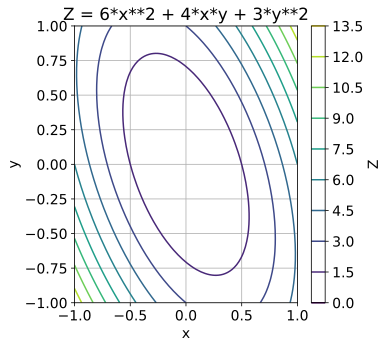

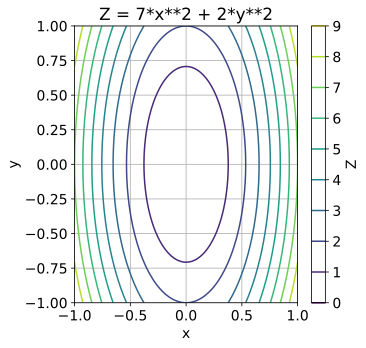

In [72]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the quadratic form function
def quadratic_form1(x, y):
    return 6*x**2 + 4*x*y + 3*y**2

def quadratic_form2(x, y):
    return 7*x**2 + 2*y**2

# 2. Create a grid of points
x_range = np.linspace(-1, 1, 100)
y_range = np.linspace(-1, 1, 100)
X, Y = np.meshgrid(x_range, y_range)

# 3. Calculate the function values
Z1 = quadratic_form1(X, Y)
Z2 = quadratic_form2(X, Y)

# 4. Plot the contour lines
plt.figure(figsize=(5, 5))
plt.contour(X, Y, Z1, levels=10, cmap='viridis') # Plot 10 level curves

plt.colorbar(label='Z')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Z = 6*x**2 + 4*x*y + 3*y**2')
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 5))
plt.contour(X, Y, Z2, levels=10, cmap='viridis') # Plot 10 level curves

plt.colorbar(label='Z')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Z = 7*x**2 + 2*y**2')
plt.grid(True)
plt.show()

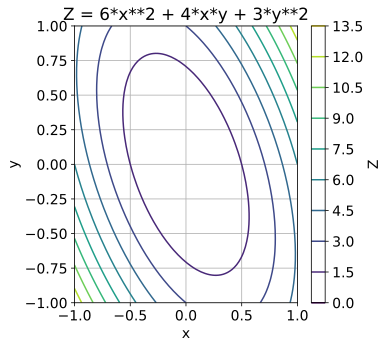

In [73]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[6,2], [2,3]])
n_points = 100

u = np.linspace(-1, 1, 100)
x, y = np.meshgrid(u, u)

X = np.vstack([x.flatten(), y.flatten()])
f_x = np.dot(np.dot(X.T, A), X)
f_x = np.diag(f_x).reshape(n_points, n_points)


plt.figure(figsize=(5, 5))
plt.contour(x, y, f_x, levels=10, cmap='viridis') # Plot 10 level curves

plt.colorbar(label='Z')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Z = 6*x**2 + 4*x*y + 3*y**2')
plt.grid(True)
plt.show()

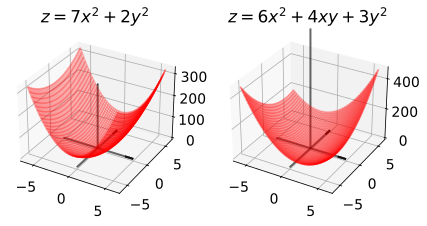

In [74]:

k = 6
x = np.linspace(-k, k)
y = np.linspace(-k, k)
X, Y = np.meshgrid(x, y)

fig = plt.figure(figsize = (7, 7))

########################### xAx 1 ############################
Z = 7*X**2 + 2*Y**2
ax = fig.add_subplot(221, projection='3d')
ax.plot_wireframe(X, Y, Z, linewidth = 1.5, alpha = .3, color = 'r')
ax.set_title('$z = 7x^2+2y^2$')

xarrow = np.array([[-5, 0, 0, 10, 0, 0]])
X1, Y1, Z1, U1, V1, W1 = zip(*xarrow)
ax.quiver(X1, Y1, Z1, U1, V1, W1, length=1, normalize=False, color = 'black',
          alpha = .6, arrow_length_ratio = .12, pivot = 'tail',
          linestyles = 'solid',linewidths = 2)

yarrow = np.array([[0, -5, 0, 0, 10, 0]])
X2, Y2, Z2, U2, V2, W2 = zip(*yarrow)
ax.quiver(X2, Y2, Z2, U2, V2, W2, length=1, normalize=False, color = 'black',
          alpha = .6, arrow_length_ratio = .12, pivot = 'tail',
          linestyles = 'solid',linewidths = 2)

zarrow = np.array([[0, 0, -3, 0, 0, 300]])
X3, Y3, Z3, U3, V3, W3 = zip(*zarrow)
ax.quiver(X3, Y3, Z3, U3, V3, W3, length=1, normalize=False, color = 'black',
alpha = .6, arrow_length_ratio = .001, pivot = 'tail',
          linestyles = 'solid',linewidths = 2)

########################### xAx 2 ############################
Z = 6*X**2 + 4*X*Y + 3*Y**2
ax = fig.add_subplot(222, projection='3d')
ax.plot_wireframe(X, Y, Z, linewidth = 1.5, alpha = .3, color = 'r')
ax.set_title('$z = 6x^2 + 4xy + 3y^2$')
xarrow = np.array([[-5, 0, 0, 10, 0, 0]])
X1, Y1, Z1, U1, V1, W1 = zip(*xarrow)
ax.quiver(X1, Y1, Z1, U1, V1, W1, length=1, normalize=False, color = 'black',
          alpha = .6, arrow_length_ratio = .12, pivot = 'tail',
          linestyles = 'solid',linewidths = 2)

yarrow = np.array([[0, -5, 0, 0, 10, 0]])
X2, Y2, Z2, U2, V2, W2 = zip(*yarrow)
ax.quiver(X2, Y2, Z2, U2, V2, W2, length=1, normalize=False, color = 'black',
          alpha = .6, arrow_length_ratio = .12, pivot = 'tail',
          linestyles = 'solid',linewidths = 2)

zarrow = np.array([[0, 0, -3, 0, 0, 800]])
X3, Y3, Z3, U3, V3, W3 = zip(*zarrow)
ax.quiver(X3, Y3, Z3, U3, V3, W3, length=1, normalize=False, color = 'black',
          alpha = .6, arrow_length_ratio = .001, pivot = 'tail',
          linestyles = 'solid',linewidths = 2)

plt.show()

## Principal Component Analysis (PCA)

---

Exploratory data analysis is an approach of analyzing data sets to summarize their main characteristics. Consider data sampled from a low-dimensional space with added noise

\begin{equation}
X_i \sim U(S^k) + N(0,\sigma^2)
\end{equation}

We'll refer to the data $\{X_i\}$ as a point cloud.  Let's represent this point cloud using an $n\times d$ numpy array, where $n$ is the number of samples, and $d$ is the dimension of the space:

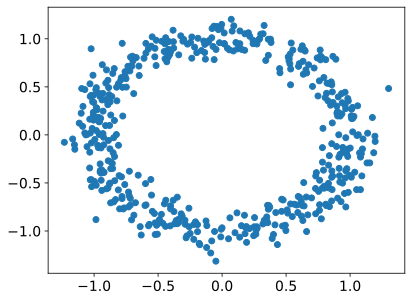

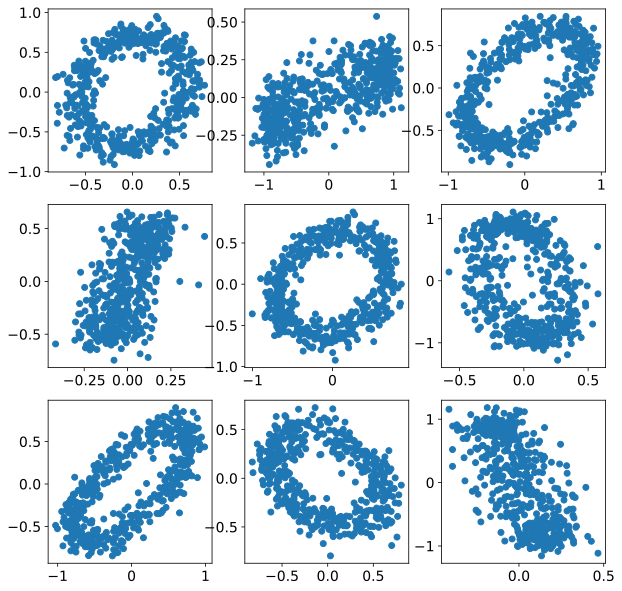

In [75]:
def sample_noisy_data(n, **kw):
    """
    Sample n points uniformly at random from the k-sphere
    embedded in d dimensions.

    Add normal nosie with variance sigma

    Arguments:
        n - number of samples

    Optional arguments:
        r - radius of circle (default 1.0)
        k - dimension of sphere (default k = 1 == circle)
        sigma - noise variance (default 0.1)
        d - dimension of embedded space (default k+1)
    """

    r = kw.get('r', 1.0)
    k = kw.get('k', 1)
    sigma = kw.get('sigma', 0.1)
    d = kw.get('d', k+1) # dimension of space

    X = np.random.randn(n,k+1) # generate random samples from standard normal distribution
    X = r * X / np.linalg.norm(X, axis=1).reshape(n,-1) # project onto sphere

    # taking the Q factor of QR factorization of random normal matrix to sample random subspaces
    Q, R = np.linalg.qr(np.random.randn(d, k+1))
    X = X @ Q.T # apply random rotation

    return X + sigma*np.random.randn(n,d)

X = sample_noisy_data(500)

plt.scatter(X[:,0], X[:,1])
plt.show()

m, n = 3,3
fig, ax = plt.subplots(m,n, figsize=(10,10))
for i in range(m):
    for j in range(n):
        X = sample_noisy_data(500, d=5)

        ax[i,j].scatter(X[:,0], X[:,1])

plt.show(fig)

In [76]:

# Plotly lets you create Javascript visualizations

import plotly
import plotly.graph_objects as go

X = sample_noisy_data(500, d=3)
fig = go.Figure(data=[go.Scatter3d(x=X[:,0], y=X[:,1], z=X[:,2],
                                   mode='markers', marker=dict(size=1))])
fig.show()

In [77]:
def quick_scatter(X):
    fig = go.Figure(data=[go.Scatter3d(x=X[:,0], y=X[:,1], z=X[:,2],
                                   mode='markers',marker=dict(size=1))])
    fig.show()

quick_scatter(X)

## Dimension Reduction

Dimensionality reduction, or dimension reduction, is the transformation of data from a high-dimensional space into a low-dimensional space so that the low-dimensional representation retains some meaningful properties of the original data, ideally close to its intrinsic dimension. It can be thought of data being sampled from a low-dimensional (parameter) space, but embedded in a high-dimensional feature space (perhaps with some noise).

Working in high-dimensional spaces can be undesirable for many reasons; raw data are often sparse as a consequence of the curse of dimensionality, and analyzing the data is usually computationally intractable.

### Principal Component Analysis (PCA)

The simplest way to reduce the dimension of real-valued data is through a linear projection.

In [78]:
X = sample_noisy_data(500, d=100, sigma=0.1)
Q, R = np.linalg.qr(np.random.randn(X.shape[1], 3))
X2 = X @ Q # a random projection isn't useful.

quick_scatter(X)

A random projection above isn't useful. PCA can be used to find the best $d$-dimensional subspace as the $d$-dimensional subspace with the largest variance in the data.

Consider an independent, identically distributed dataset, $X=\{x_1,x_2, \cdots, x_n\}$, where $x_i\in{\mathbb R}^D$, with mean 0 that possesses the data covariance matrix:
$$\hat{\Sigma} = \frac{1}{n}\sum_{i=1}^N x_ix_i^T= \frac{1}{n}X^T X$$
Note that $X$ is a $D \times N$ matrix, and $\hat{\Sigma}$ empirical covariance matrix, which is symmetric, positive semidefinite.

Let $v$ be a unit vector.  The projection onto the subspace spanned by $v$ is calculated as $X v$.  $Xv$ will also have zero mean. The variance in this 1-dimensional subspace is then
$$\sigma(v) = \frac{1}{n} (Xv)^T (Xv) = \frac{1}{n} v^T X^T X v$$

So the subspace with the largest variance is defined by the unit vector $v$ which maximizes
$$v^T (\frac{1}{n} X^T X) v = v^T \hat{\Sigma} v,$$
which can be written as the variational problem

$$
\operatorname{maximze}_{v\in \mathbb{R}^n} v^T \hat{\Sigma} v\\
\text{subject to } \|v\|_2 = 1
$$

This is the same problem as finding the largest magnitude eigenpair of $\hat{\Sigma}$, where $v$ is the eigenvector, and the eigenvalue of $v$ is $\sigma(v)$.

If we want to project into a $k+1$ dimensional space, we then find
$$
\operatorname{maximze}_{v\in \mathbb{R}^n} v^T \hat{\Sigma} v\\
\text{subject to } \|v\|_2 = 1, v^T V_k = 0
$$
where $V_k = [v_1,\dots,v_k]$ spans the optimal $k$-dimensional subspace.

This boils down to finding the largest $k+1$ dimensional eigenspace of $\hat{\Sigma}$.

The vectors $v_1,\dots, v_k$ are known as the **principal components** of $X$.

<img src="https://drive.google.com/uc?export=view&id=1Jx-VHWS9R9IIBnmKUML65Bm9UsdxP2X6" width="500">

[//]: #![](https://drive.google.com/uc?export=view&id=1Jx-VHWS9R9IIBnmKUML65Bm9UsdxP2X6)

<img src="https://drive.google.com/uc?export=view&id=1pdHwgq6dy0jKqZKY9L_Nv2diacu3h1FG" width="500">


[//]: #![](https://drive.google.com/uc?export=view&id=1pdHwgq6dy0jKqZKY9L_Nv2diacu3h1FG)

PCA as a dimensionality reduction algorithm maximizes the variance in the low-dimensional representation of the data to retain as much information as possible. We can obtain the basis of the principal subspace as the eigenvectors that are associated with the largest eigenvalues of the data covariance matrix:

$$\hat{\Sigma} = \frac{1}{n}\sum_{i=1}^N x_ix_i^T= \frac{1}{n}X^T X$$


If $X = U \Sigma V^T$ then
$$X^T X = V \Sigma^T U^T U \Sigma V^T = V \Sigma^2 V^T$$
Clearly, the right-singular vectors $V$ are the eigenvectors of $X^T X$. With this, we get that the columns of $V$ are the
eigenvectors of $XX^T$ (and therefore $\hat{\Sigma}$). Furthermore, the eigenvalues of $\hat{\Sigma}$, $\lambda_d$, are related to the singular values of $X$ by:
$$\lambda_d = \frac{\sigma^2_d}{N}$$
This relationship between the eigenvalues of $\hat{\Sigma}$ and the singular values of $X$ provides the connection between the maximum variance view and the singular value decomposition. Therefore we can perform an eigendecomposition and compute the eigenvalues and eigenvectors of $\hat{\Sigma}$ directly.
We use a singular value decomposition of $\hat{\Sigma}$, which is symmetric and factorizes into $XX^T$ (ignoring the factor N), and the eigenvalues of $\hat{\Sigma}$ are the squared singular values of $X$.

<img src="https://drive.google.com/uc?export=view&id=1mf9JeCyUEX917uXK_-aTbducFyuBkk5p" width="500">

In [79]:
def mean_center(X):
    mu = np.average(X, axis=0) # 1^T X / n
    return X - mu

def variance(X):
    n = X.shape[0]
    X = mean_center(X)
    X = X/np.std(X)
    return X.T @ X / n

def principal_vectors(X, k=3):
    Sigma = variance(X)
    lam, V = np.linalg.eigh(Sigma)
    return V[:,-k:] # eigenvalues in increasing order

def pca_projection(X, k=3):
    V = principal_vectors(X, k=k)
    return X @ V


X = sample_noisy_data(1000, d=100, sigma=0.1)

Xpca = pca_projection(X, k=3)

quick_scatter(Xpca)


#### PCA Via SVD

In practice, you **should not** compute PCA by forming $X^T X$.  Why?  Because if $X$ is ill-conditioned, then $X^T X$ will be even more ill conditioned.

What you should do is use the SVD of $X$.  If $X = U \Sigma V^T$ then
$$X^T X = V \Sigma^T U^T U \Sigma V^T = V \Sigma^2 V^T$$
Clearly, the right-singular vectors $V$ are the eigenvectors of $X^T X$.

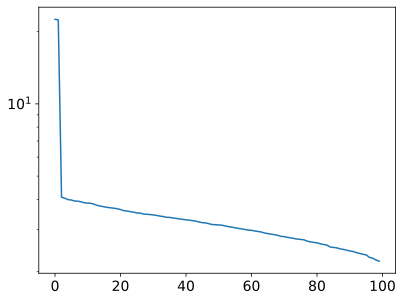

In [80]:
X = sample_noisy_data(1000, d=100, sigma=0.1)
u, s, v = np.linalg.svd(X)
plt.semilogy(s)
plt.show()

#### HW6-1

1. Write a function to project a design matrix `X` onto its top `k` principal components using the SVD.
2. Modify your function to use `scipy.sparse.linalg.svds`.
3. What is the condition number $\kappa(X^T X)$ expressed in terms of $\kappa(X)$?
4. Plot the singular values of `X` generated above - how might you decide how many principal components to use?

#### HW6-2
1. Generate synthetic random data with a linear trend along a line and perform your PCA to find the principal components of the data.
2. Plot the original data, reconstructed data (projected data onto the principal component), along the principal components as vectors.
3. Try omitting the centering step in PCA, how do things change?
4. Add a single outlying point to your data; How do the principal components change?

### HW6-1

(1000, 3)


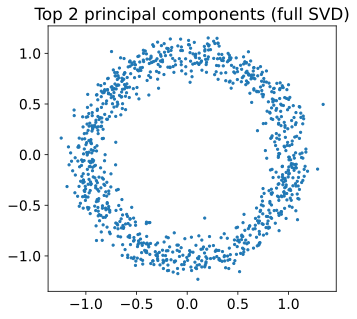

In [81]:
# HW6-1 (1): PCA projection using the SVD
import numpy as np
import matplotlib.pyplot as plt

def pca_svd(X, k=3):
    Xc = X - X.mean(axis=0)                  # center the data
    U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:k].T                     # project onto top k directions

X = sample_noisy_data(1000, d=100, sigma=0.1)
Xp = pca_svd(X, k=3)
print(Xp.shape)

plt.scatter(Xp[:,0], Xp[:,1], s=5)
plt.gca().set_aspect('equal')
plt.title('Top 2 principal components (full SVD)')
plt.show()

In [82]:
# HW6-1 (2): same thing with scipy.sparse.linalg.svds (only computes k singular vectors)
from scipy.sparse.linalg import svds

def pca_svds(X, k=3):
    Xc = X - X.mean(axis=0)
    U, s, Vt = svds(Xc, k=k)
    idx = np.argsort(s)[::-1]                # svds returns them smallest first
    return Xc @ Vt[idx].T

Xp2 = pca_svds(X, k=3)

# should match the full SVD up to a sign flip on each column
print('max difference (ignoring sign):', np.abs(np.abs(Xp) - np.abs(Xp2)).max())

max difference (ignoring sign): 1.1157741397482823e-14


In [83]:
# HW6-1 (3): condition number of X^T X vs X
A = np.random.randn(50, 10) @ np.diag(np.logspace(0, -3, 10))   # somewhat ill-conditioned
print('kappa(X)     =', np.linalg.cond(A))
print('kappa(X)^2   =', np.linalg.cond(A)**2)
print('kappa(X^T X) =', np.linalg.cond(A.T @ A))

kappa(X)     = 1110.28935342115
kappa(X)^2   = 1232742.4483203555
kappa(X^T X) = 1232742.448320354


**Answer (3):** $\kappa(X^TX) = \kappa(X)^2$. If $X = U\Sigma V^T$ then $X^TX = V\Sigma^2V^T$, so the singular values get squared and $\sigma_{max}^2/\sigma_{min}^2 = \kappa(X)^2$. That's why we do PCA with the SVD of $X$ instead of forming $X^TX$: if $\kappa(X)=10^8$ then $\kappa(X^TX)=10^{16}$ and you lose basically all your digits.

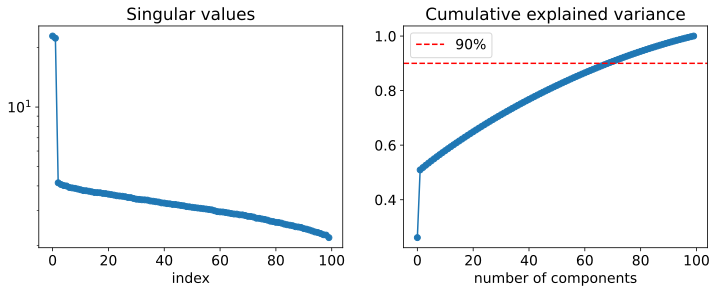

first 5 singular values: [22.83 22.26  4.15  4.07  4.02]


In [84]:
# HW6-1 (4): singular values of X
Xc = X - X.mean(axis=0)
s = np.linalg.svd(Xc, compute_uv=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(s, 'o-')
ax[0].set_xlabel('index'); ax[0].set_title('Singular values')

explained = np.cumsum(s**2) / np.sum(s**2)
ax[1].plot(explained, 'o-')
ax[1].axhline(0.9, color='r', ls='--', label='90%')
ax[1].set_xlabel('number of components'); ax[1].set_title('Cumulative explained variance')
ax[1].legend()
plt.show()

print('first 5 singular values:', np.round(s[:5], 2))

**Answer (4):** There are 2 big singular values and then everything drops to a flat "noise floor". That makes sense since the data is a circle (lives in a 2D plane) with noise added in all 100 directions. So you'd pick **2 components**.

Ways to decide in general:
- look for the "elbow"/big gap in the singular value plot (scree plot)
- keep enough components to explain some % of the variance (like 90–95%) — though here the noise is spread over 98 directions, so it adds up and this rule asks for more components than the gap does
- anything at the noise floor level is just noise, so ignore it

### HW6-2

In [85]:
# HW6-2 (1): synthetic data along a line + PCA
np.random.seed(0)
n = 100
x = np.random.uniform(0, 10, n)
y = 0.5*x + 2 + np.random.randn(n)*0.5      # line y = 0.5x + 2 plus noise
X = np.column_stack((x, y))

def pca(X, center=True):
    mu = X.mean(axis=0) if center else np.zeros(X.shape[1])
    Xc = X - mu
    U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
    var = s**2 / X.shape[0]                  # variance along each PC
    return mu, Vt.T, var                     # columns of V = principal components

mu, V, var = pca(X)
print('principal components (columns):\n', V)
print('variance along each PC:', var)
print('fraction explained by PC1:', var[0]/var.sum())
print('slope of PC1:', V[1,0]/V[0,0], '(true slope 0.5)')

principal components (columns):
 [[-0.89120552  0.45359974]
 [-0.45359974 -0.89120552]]
variance along each PC: [10.41367892  0.1980312 ]
fraction explained by PC1: 0.9813384274930326
slope of PC1: 0.5089732219437124 (true slope 0.5)


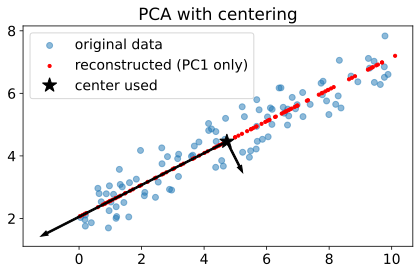

In [86]:
# HW6-2 (2): plot original data, reconstruction from PC1, and PC vectors
def plot_pca(X, mu, V, var, title=''):
    v1 = V[:, 0]
    X_rec = mu + np.outer((X - mu) @ v1, v1)   # project onto PC1 and map back

    plt.figure(figsize=(7, 7))
    plt.scatter(X[:,0], X[:,1], alpha=0.5, label='original data')
    plt.scatter(X_rec[:,0], X_rec[:,1], color='red', s=10, label='reconstructed (PC1 only)')
    for i in range(2):
        L = 2*np.sqrt(var[i])                  # arrow length = 2 std devs
        plt.arrow(mu[0], mu[1], L*V[0,i], L*V[1,i], width=0.05, color='k')
    plt.plot(*mu, 'k*', markersize=15, label='center used')
    plt.gca().set_aspect('equal')
    plt.legend(); plt.title(title)
    plt.show()

plot_pca(X, mu, V, var, 'PCA with centering')

Basically all the variance (~98%) is in PC1, which points along the line with slope ≈ 0.5. PC2 is the short arrow perpendicular to it, which is just the noise. The red reconstructed points sit right on the best-fit line.

PC1 without centering: [-0.76343619 -0.64588326]  slope = 0.8460212680065691
PC1 with centering:    [-0.89120552 -0.45359974]  slope = 0.5089732219437124


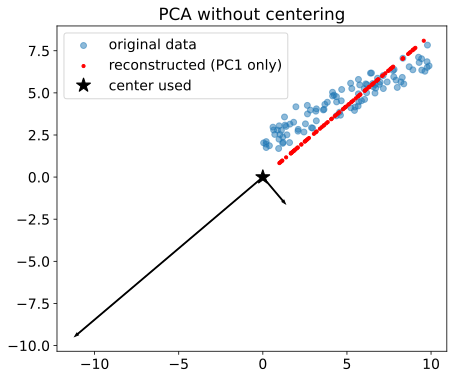

In [87]:
# HW6-2 (3): skip the centering step
mu0, V0, var0 = pca(X, center=False)
print('PC1 without centering:', V0[:,0], ' slope =', V0[1,0]/V0[0,0])
print('PC1 with centering:   ', V[:,0],  ' slope =', V[1,0]/V[0,0])
plot_pca(X, mu0, V0, var0, 'PCA without centering')

**Answer (3):** Without centering, the line PCA finds has to go through the origin instead of through the middle of the data. So PC1 ends up pointing from the origin toward the data cloud (the mean), not along the trend — the slope comes out wrong (≈0.85 here vs. ≈0.51 with centering). The red reconstructed points no longer sit on the trend line, and the "variance" numbers are really just $\|x\|^2$ from the origin, so they don't mean much. The further the data is from the origin, the worse it gets.

PC1 without outlier: [-0.89120552 -0.45359974]  slope = 0.5089732219437124
PC1 with outlier:    [-0.87863563 -0.47749286]  slope = 0.5434481017663572
fraction explained by PC1: 0.9813384274930326 -> 0.8888227373812554


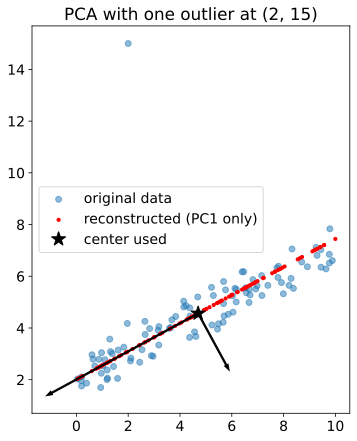

In [88]:
# HW6-2 (4): add one outlier
X_out = np.vstack((X, [2, 15]))              # one point way off the line
mu_o, V_o, var_o = pca(X_out)
print('PC1 without outlier:', V[:,0],   ' slope =', V[1,0]/V[0,0])
print('PC1 with outlier:   ', V_o[:,0], ' slope =', V_o[1,0]/V_o[0,0])
print('fraction explained by PC1:', var[0]/var.sum(), '->', var_o[0]/var_o.sum())
plot_pca(X_out, mu_o, V_o, var_o, 'PCA with one outlier at (2, 15)')

**Answer (4):** Just one bad point tilts PC1 toward it (slope goes from ≈0.51 to ≈0.54), shifts the mean a bit, and drops the variance explained by PC1 from ~98% to ~89%. That's a lot for 1 point out of 101! It happens because PCA minimizes *squared* distances, so a far-away point has a huge pull. So PCA is not robust to outliers — which is why things like Robust PCA ($M = L + S$, mentioned above) exist.